# Connections puzzles: reproducible statistical learning (BERN02)

## Research question
**How do the words and semantic relationships in a Connections puzzle relate to its published difficulty rating?**

This is a complete, readable report: every table and plot is created below. We use only methods for data handling, visualization, statistical modeling, prediction, dimension reduction, clustering, and model evaluation.

**Difficulty** is a published rating (higher means harder). A missing rating is marked ''None''.

## 1. Setup and reproducible workflow

Using common libraries and keeping all data files in `data/`. All paths are relative to the project directory, so the notebook can be rerun on any machine.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

DATA = Path("data")
OUTPUT = DATA / "derived"
OUTPUT.mkdir(parents=True, exist_ok=True)

words = pd.read_csv(DATA / "raw" / "connections2.csv")
groups = pd.read_csv(DATA / "semantic_source" / "semantic_group_statistics.csv")
pairs = pd.read_csv(DATA / "semantic_source" / "semantic_pair_statistics.csv")

words["puzzle_date"] = pd.to_datetime(words["puzzle_date"])
groups["puzzle_date"] = pd.to_datetime(groups["puzzle_id"].str.split("_").str[0])
pairs["puzzle_date"] = pd.to_datetime(pairs["puzzle_id"].str.split("_").str[0])

print("Word rows:", len(words))
print("Puzzles:", words["puzzle_date"].nunique())
print("Pairwise similarity scores:", len(pairs))
display(words.head())

Word rows: 19504
Puzzles: 1219
Pairwise similarity scores: 146280


,puzzle_date,puzzle_number,difficulty,color,category,position,word
0,2023-06-12,1,NaN,yellow,WET WEATHER,1,HAIL
1,2023-06-12,1,NaN,yellow,WET WEATHER,2,RAIN
2,2023-06-12,1,NaN,yellow,WET WEATHER,3,SLEET
3,2023-06-12,1,NaN,yellow,WET WEATHER,4,SNOW
4,2023-06-12,1,NaN,green,NBA TEAMS,1,BUCKS


## 2. Data quality and missing ratings

A standard puzzle should have 16 words and four categories. Check this before analysis, and inspect which years have difficulty ratings.

In [3]:
quality = words.groupby("puzzle_date").agg(
    word_rows=("word", "size"),
    unique_words=("word", "nunique"),
    categories=("category", "nunique"),
    rating=("difficulty", "first")
).reset_index()

print("Puzzles without exactly 16 rows:", (quality["word_rows"] != 16).sum())
print("Puzzles without 16 unique words:", (quality["unique_words"] != 16).sum())
print("Puzzles without 4 categories:", (quality["categories"] != 4).sum())

display(quality.loc[(quality["word_rows"] != 16) | (quality["unique_words"] != 16)])

quality["year"] = quality["puzzle_date"].dt.year
quality["has_rating"] = quality["rating"].notna()
coverage = quality.groupby("year").agg(
    total_puzzles=("puzzle_date", "size"),
    rated_puzzles=("has_rating", "sum")
)
coverage["percent_rated"] = 100 * coverage["rated_puzzles"] / coverage["total_puzzles"]
display(coverage)
quality.to_csv(OUTPUT / "quality_check.csv", index=False)
coverage.to_csv(OUTPUT / "rating_coverage.csv")

# coverage["percent_rated"].plot.bar(figsize=(7, 4))
# plt.ylabel("Puzzles with a rating (%)")
# plt.title("Rating coverage by year")
# plt.tight_layout()
# plt.show()

Puzzles without exactly 16 rows: 0
Puzzles without 16 unique words: 2
Puzzles without 4 categories: 0


,puzzle_date,word_rows,unique_words,categories,rating
61,2023-08-12,16,15,4,NaN
1123,2026-07-09,16,15,4,1.5


,total_puzzles,rated_puzzles,percent_rated
year,,,
2023,203,0,0.000000
2024,366,223,60.928962
2025,365,365,100.000000
2026,285,285,100.000000


## 3. Explore difficulty ratings over time

These are descriptive statistics, not proof that the game became easier or harder. Earlier years have fewer observed ratings.

,count,mean,median,std
year,,,,
2024,223,2.939,3.0,0.537
2025,365,2.743,2.8,0.627
2026,285,2.262,2.3,0.556


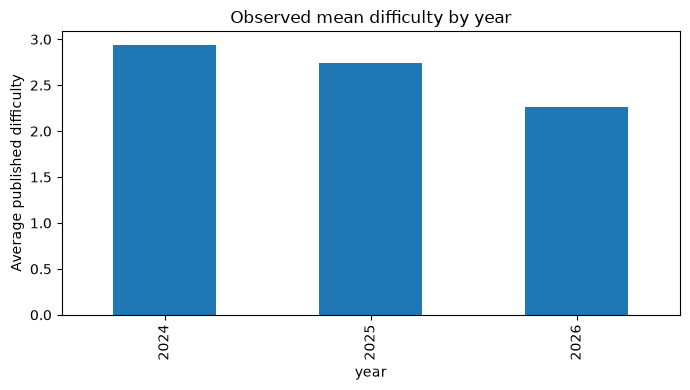

In [4]:
rated_quality = quality.dropna(subset=["rating"])
annual = rated_quality.groupby("year")["rating"].agg(["count", "mean", "median", "std"])
display(annual.round(3))
annual.to_csv(OUTPUT / "difficulty_by_year.csv")

annual["mean"].plot.bar(figsize=(7, 4))
plt.ylabel("Average published difficulty")
plt.title("Observed mean difficulty by year")
plt.tight_layout()
plt.show()

## 4. Explore semantic similarity across the four colors

The existing group statistics contain mean similarity between the four words in each correct category. We compare colors using summaries and boxplots, without assuming that similarity is identical to human difficulty.

,count,mean,median,std
color,,,,
yellow,1219,0.331,0.323,0.081
green,1219,0.317,0.309,0.074
blue,1219,0.294,0.286,0.069
purple,1219,0.264,0.261,0.059


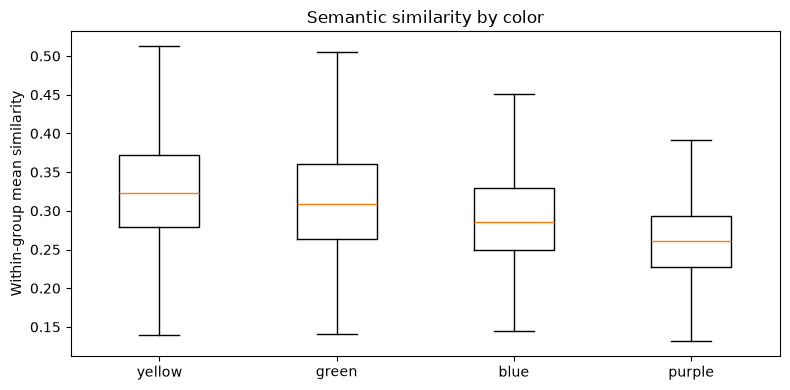

In [5]:
color_order = ["yellow", "green", "blue", "purple"]
color_summary = groups.groupby("color")["mean_similarity"].agg(["count", "mean", "median", "std"])
color_summary = color_summary.loc[color_order]
display(color_summary.round(3))
color_summary.to_csv(OUTPUT / "color_similarity_summary.csv")

color_values = [groups.loc[groups["color"] == color, "mean_similarity"] for color in color_order]
plt.figure(figsize=(8, 4))
plt.boxplot(color_values, tick_labels=color_order, showfliers=False)
plt.ylabel("Within-group mean similarity")
plt.title("Semantic similarity by color")
plt.tight_layout()
plt.show()

## 5. Build one row per puzzle

The main dataset has 16 rows per puzzle, but a regression model needs one outcome per puzzle. We calculate basic word features and summarize existing similarity scores. We do **not** treat 16 repeated ratings as 16 independent observations.

In [ ]:
# Word length
words["word_length"] = words["word"].astype(str).str.len()

# Difficulty, puzzle number, mean and std word length per puzzle
word_features = words.groupby("puzzle_date").agg(
    difficulty=("difficulty", "first"),
    puzzle_number=("puzzle_number", "first"),
    mean_word_length=("word_length", "mean"),
    sd_word_length=("word_length", "std")
).reset_index()

# Each puzzle has two kinds of pairs: words in the same group,
# and words from different groups.
pair_means = pairs.groupby(["puzzle_date", "pair_type"])["similarity"].mean().unstack()
pair_means = pair_means.rename(columns={
    "Same group": "within_group_similarity",
    "Different groups": "cross_group_similarity"
}).reset_index()

puzzles = word_features.merge(pair_means, on="puzzle_date", how="left")
puzzles["similarity_gap"] = (
    puzzles["within_group_similarity"] - puzzles["cross_group_similarity"]
)
puzzles = puzzles.sort_values("puzzle_date").reset_index(drop=True)
puzzles.to_csv(OUTPUT / "puzzle_features.csv", index=False)
display(puzzles.head())



,puzzle_date,difficulty,puzzle_number,mean_word_length,sd_word_length,cross_group_similarity,within_group_similarity,similarity_gap
0,2023-06-12,NaN,1,4.6250,1.087811,0.262901,0.374216,0.111315
1,2023-06-13,NaN,2,4.5000,1.505545,0.270310,0.311571,0.041261
2,2023-06-14,NaN,3,4.3125,1.014479,0.273129,0.333297,0.060168
3,2023-06-15,NaN,4,5.1250,1.500000,0.241150,0.312651,0.071502
4,2023-06-16,NaN,5,5.2500,1.437591,0.247925,0.317409,0.069483


In [15]:
# April 1, 2024 uses emojis rather than ordinary words
special_puzzle_date = "2024-04-01"

# Keep the original data unchanged
puzzles = puzzles.loc[
    puzzles["puzzle_date"].astype(str) != special_puzzle_date
]

## 6. Explore correlations with difficulty

Spearman correlation describes whether higher feature values tend to accompany higher ratings. A correlation is not a causal effect.

,feature,spearman_correlation,p_value
0,within_group_similarity,0.0134,0.6933
1,cross_group_similarity,0.1290,0.0001
2,similarity_gap,-0.0975,0.0039
3,mean_word_length,-0.1227,0.0003
4,sd_word_length,-0.0943,0.0053


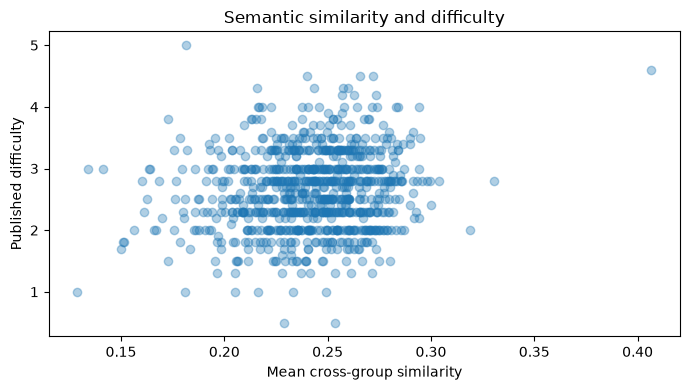

In [16]:
rated = puzzles.dropna(subset=["difficulty"]).copy()
feature_names = [
    "within_group_similarity",
    "cross_group_similarity",
    "similarity_gap",
    "mean_word_length",
    "sd_word_length"
]

correlation_rows = []
for feature in feature_names:
    complete = rated[[feature, "difficulty"]].dropna()
    correlation, p_value = spearmanr(complete[feature], complete["difficulty"])
    correlation_rows.append({
        "feature": feature,
        "spearman_correlation": correlation,
        "p_value": p_value
    })

correlations = pd.DataFrame(correlation_rows)
display(correlations.round(4))
correlations.to_csv(OUTPUT / "difficulty_correlations.csv", index=False)

plt.figure(figsize=(7, 4))
plt.scatter(rated["cross_group_similarity"], rated["difficulty"], alpha=0.35)
plt.xlabel("Mean cross-group similarity")
plt.ylabel("Published difficulty")
plt.title("Semantic similarity and difficulty")
plt.tight_layout()
plt.show()

## 7. Linear regression: explain difficulty

Fit an interpretable linear model. Coefficients describe adjusted associations, not causal effects. Including `puzzle_number` accounts for a simple linear time trend; it does not solve the missing-data problem.

We standardize the predictors so that their coefficients are more comparable.

In [17]:
regression_features = [
    # "puzzle_number",
    "within_group_similarity",
    "cross_group_similarity",
    "mean_word_length"
]
model_data = rated.dropna(subset=regression_features).copy()

scaler = StandardScaler()
X = scaler.fit_transform(model_data[regression_features])
y = model_data["difficulty"]

regression = LinearRegression()
regression.fit(X, y)

coefficients = pd.DataFrame({
    "feature": regression_features,
    "standardized_coefficient": regression.coef_
})
display(coefficients.round(3))
print("R-squared on observed data:", round(regression.score(X, y), 3))
coefficients.to_csv(OUTPUT / "linear_regression_coefficients.csv", index=False)

,feature,standardized_coefficient
0,within_group_similarity,-0.069
1,cross_group_similarity,0.123
2,mean_word_length,-0.026


R-squared on observed data: 0.031


## 8. Prediction: compare with a simple baseline

To test generalization, train on earlier puzzles and test on later ones. **Standardization is fitted only on training data**, avoiding information leakage. Compare linear regression with predicting the average training rating.

,model,MAE,RMSE,R2
0,Training mean,0.619,0.734,-0.669
1,Linear regression,0.592,0.710,-0.563


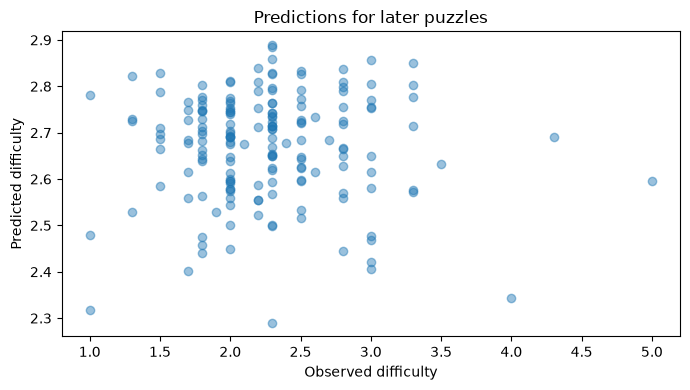

In [18]:
model_data = model_data.sort_values("puzzle_date").reset_index(drop=True)
cutoff = int(len(model_data) * 0.8)
train = model_data.iloc[:cutoff]
test = model_data.iloc[cutoff:]

train_mean = train["difficulty"].mean()
baseline_predictions = np.full(len(test), train_mean)

train_scaler = StandardScaler()
X_train = train_scaler.fit_transform(train[regression_features])
X_test = train_scaler.transform(test[regression_features])

predictor = LinearRegression()
predictor.fit(X_train, train["difficulty"])
model_predictions = predictor.predict(X_test)

comparison = pd.DataFrame({
    "model": ["Training mean", "Linear regression"],
    "MAE": [
        mean_absolute_error(test["difficulty"], baseline_predictions),
        mean_absolute_error(test["difficulty"], model_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test["difficulty"], baseline_predictions)),
        np.sqrt(mean_squared_error(test["difficulty"], model_predictions))
    ],
    "R2": [
        r2_score(test["difficulty"], baseline_predictions),
        r2_score(test["difficulty"], model_predictions)
    ]
})
display(comparison.round(3))
comparison.to_csv(OUTPUT / "prediction_comparison.csv", index=False)

plt.figure(figsize=(7, 4))
plt.scatter(test["difficulty"], model_predictions, alpha=0.45)
plt.xlabel("Observed difficulty")
plt.ylabel("Predicted difficulty")
plt.title("Predictions for later puzzles")
plt.tight_layout()
plt.show()

## 9. Cross-validation: check whether results depend on the time period

The syllabus mentions cross-validation. Here we use **time-series cross-validation**, which trains on earlier observations and validates on later ones. We standardize separately within each fold.

In [19]:
time_splits = TimeSeriesSplit(n_splits=5)
fold_results = []

for fold, (train_indices, test_indices) in enumerate(time_splits.split(model_data), start=1):
    fold_train = model_data.iloc[train_indices]
    fold_test = model_data.iloc[test_indices]

    fold_scaler = StandardScaler()
    fold_X_train = fold_scaler.fit_transform(fold_train[regression_features])
    fold_X_test = fold_scaler.transform(fold_test[regression_features])

    fold_model = LinearRegression()
    fold_model.fit(fold_X_train, fold_train["difficulty"])
    predictions = fold_model.predict(fold_X_test)

    fold_results.append({
        "fold": fold,
        "linear_regression_MAE": mean_absolute_error(fold_test["difficulty"], predictions),
        "mean_baseline_MAE": mean_absolute_error(
            fold_test["difficulty"],
            np.full(len(fold_test), fold_train["difficulty"].mean())
        )
    })

cross_validation = pd.DataFrame(fold_results)
display(cross_validation.round(3))
print("Average regression MAE:", round(cross_validation["linear_regression_MAE"].mean(), 3))
cross_validation.to_csv(OUTPUT / "time_series_cross_validation.csv", index=False)

,fold,linear_regression_MAE,mean_baseline_MAE
0,1,0.438,0.451
1,2,0.494,0.478
2,3,0.559,0.570
3,4,0.687,0.681
4,5,0.550,0.586


Average regression MAE: 0.546


## 10. Principal component analysis (PCA)

PCA is a dimension-reduction method included in the course's broad statistical-learning scope. It summarizes correlated numerical features into a smaller number of axes. We use PCA **for exploration**, not to claim the components represent true psychological difficulty.

Variance explained by PC1 and PC2: [0.675 0.18 ]


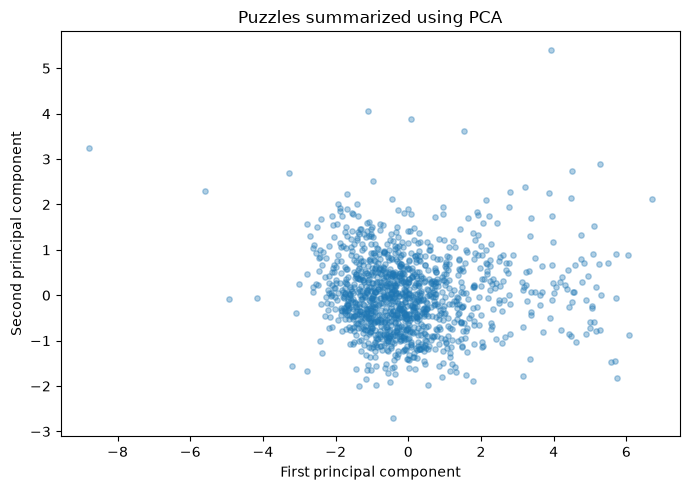

In [20]:
structure_features = [
    "within_group_similarity",
    "cross_group_similarity",
    "mean_word_length",
    "sd_word_length"
]
structure_data = puzzles.dropna(subset=structure_features).copy()

scaled_structure = StandardScaler().fit_transform(structure_data[structure_features])
pca = PCA(n_components=2)
coordinates = pca.fit_transform(scaled_structure)

print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_, 3))
plt.figure(figsize=(7, 5))
plt.scatter(coordinates[:, 0], coordinates[:, 1], alpha=0.35, s=15)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("Puzzles summarized using PCA")
plt.tight_layout()
plt.show()

pca_table = pd.DataFrame({
    "puzzle_date": structure_data["puzzle_date"],
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1]
})
pca_table.to_csv(OUTPUT / "pca_coordinates.csv", index=False)

## 11. K-means clustering

Clustering groups puzzles with similar numerical properties **without using difficulty labels**. We choose three clusters as an illustrative example, not as a scientifically established number of puzzle types. Compare their average ratings only after clustering.

,puzzles,mean_difficulty,mean_within_similarity,mean_cross_similarity
cluster,,,,
0,547,2.631,0.287,0.238
1,532,2.698,0.328,0.266
2,139,2.517,0.251,0.201


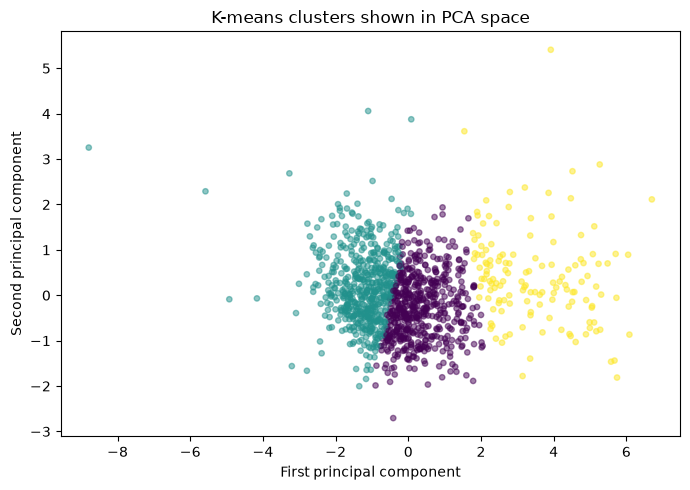

In [21]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
structure_data["cluster"] = kmeans.fit_predict(scaled_structure)

cluster_summary = structure_data.groupby("cluster").agg(
    puzzles=("puzzle_date", "size"),
    mean_difficulty=("difficulty", "mean"),
    mean_within_similarity=("within_group_similarity", "mean"),
    mean_cross_similarity=("cross_group_similarity", "mean")
)
display(cluster_summary.round(3))
cluster_summary.to_csv(OUTPUT / "cluster_summary.csv")
structure_data[["puzzle_date", "cluster"]].to_csv(OUTPUT / "puzzle_clusters.csv", index=False)

plt.figure(figsize=(7, 5))
plt.scatter(coordinates[:, 0], coordinates[:, 1], c=structure_data["cluster"], alpha=0.5, s=15)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("K-means clusters shown in PCA space")
plt.tight_layout()
plt.show()

## 12. Word and category recurrence

Use the complete word-level database, including puzzles with missing difficulty. These simple frequency tables show which words and category labels reappear. Exact category labels may differ even when they describe the same idea.

In [23]:
word_frequency = words.groupby("word").agg(
    appearances=("word", "size"),
    puzzles_used=("puzzle_date", "nunique")
).sort_values("appearances", ascending=False)

category_frequency = words.groupby("category").agg(
    word_entries=("word", "size"),
    puzzles_used=("puzzle_date", "nunique")
).sort_values("puzzles_used", ascending=False)

display(word_frequency.head(15))
display(category_frequency.head(15))
word_frequency.to_csv(OUTPUT / "word_frequency.csv")
category_frequency.to_csv(OUTPUT / "category_frequency.csv")

,appearances,puzzles_used
word,,
BALL,30,30
RING,25,25
BAR,22,22
FLY,22,22
CHECK,21,21
LEAD,20,20
BLUE,19,19
WING,19,19
JACK,19,19


,word_entries,puzzles_used
category,,
ANAGRAMS,40,10
HOMOPHONES,40,10
FISH,32,8
PALINDROMES,24,6
THINGS THAT ARE RED,24,6
MAGAZINES,24,6
MUSICAL INSTRUMENTS,20,5
EAT VORACIOUSLY,20,5
MUSIC GENRES,20,5


## 13. Discussion, limitations and conclusions

**What this analysis can answer:**

- How semantic similarity differs across colors and over puzzles.
- Whether basic word and similarity features are associated with published difficulty.
- Whether an interpretable regression predicts future ratings better than a simple baseline.
- Whether puzzles show recurring numerical patterns through PCA and clustering.

**What it cannot establish:**

- Causation: the statistical associations do not prove why a puzzle is difficult.
- Individual distractor connections: the pairwise CSV does not include the identities of the two words for each score.
- Human solver behavior: published ratings are not direct measurements of each player's mistakes or solving time.
- Unbiased time trends: missing difficulty values are not evenly distributed across years.

**Research conclusion template (fill in after running):**

> We analyzed the Connections database using descriptive statistics, regression, chronological evaluation, PCA and clustering. We compared a model based on semantic and lexical features with a baseline and examined its out-of-time error. The results suggest [insert the supported findings], while the incomplete rating coverage and limited semantic features restrict the conclusions.

### Reproducibility checklist

1. All inputs and outputs are CSV files inside `data/`.
2. Every result is generated in notebook order; no hidden precomputed model is required.
3. Random seed 42 is fixed for K-means.
4. Train/test splits respect puzzle chronology.
5. All transformations for prediction are fitted only on training data.
6. The notebook contains both code and interpretation, as required for literate programming.

## 14. Predicting the solution to an unseen puzzle

**Research question:** Can statistical learning assign 16 words to four groups of four?

We train a **logistic regression classifier** on word pairs from earlier puzzles. A positive pair belongs to the same solution group. For a new puzzle, we predict the probability for each of its 120 pairs, then form four groups of four with a simple, readable greedy grouping procedure.

The features use only the word spellings and patterns learned from **earlier** puzzles. We do **not** use the solution colors or categories of the puzzle being predicted. This is a baseline, not a complete semantic understanding of wordplay. We compare against random grouping and evaluate on later, unseen puzzles.

The course covers classification, model evaluation and reproducible workflows; the greedy grouping rule is a small post-processing step required by the puzzle's four-by-four format.

In [24]:
from itertools import combinations
from collections import defaultdict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

# One record for each puzzle. Sort by date before splitting.
puzzle_records = []
for date, rows in words.groupby("puzzle_date"):
    rows = rows.sort_values(["color", "position"])
    puzzle_records.append({
        "date": date,
        "words": rows["word"].astype(str).str.upper().tolist(),
        "groups": rows["color"].tolist()
    })

puzzle_records.sort(key=lambda puzzle: puzzle["date"])

# Reserve the most recent 20% of puzzles for testing.
split_index = int(0.8 * len(puzzle_records))
training_puzzles = puzzle_records[:split_index]
testing_puzzles = puzzle_records[split_index:]

print("Training puzzles:", len(training_puzzles))
print("Unseen test puzzles:", len(testing_puzzles))


Training puzzles: 975
Unseen test puzzles: 244


### 14.1 Construct pair features

The classifier sees five easy-to-explain features: character similarity, shared first letter, shared last letter, length difference, and whether the two words have appeared together in an earlier solution group. We use character TF-IDF for spelling similarity; it does not require a downloaded language model. The historical-pair feature is constructed **only from training puzzles**.

In [25]:
# Character n-grams capture similarities in spelling.
training_words = [word for puzzle in training_puzzles for word in puzzle["words"]]
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 3))
vectorizer.fit(training_words)

# Remember pairs that have appeared together in training solutions.
previous_pairs = set()
for puzzle in training_puzzles:
    for i, j in combinations(range(16), 2):
        if puzzle["groups"][i] == puzzle["groups"][j]:
            pair = tuple(sorted((puzzle["words"][i], puzzle["words"][j])))
            previous_pairs.add(pair)


def pair_features(puzzle_words):
    """Return five readable features for all 120 word pairs."""
    word_vectors = vectorizer.transform(puzzle_words)
    similarities = (word_vectors @ word_vectors.T).toarray()
    features = []
    pair_indices = []

    for i, j in combinations(range(16), 2):
        first = puzzle_words[i]
        second = puzzle_words[j]
        old_pair = tuple(sorted((first, second)))

        features.append([
            similarities[i, j],
            int(first[0] == second[0]),
            int(first[-1] == second[-1]),
            abs(len(first) - len(second)),
            int(old_pair in previous_pairs)
        ])
        pair_indices.append((i, j))

    return np.array(features), pair_indices


# Each training puzzle contributes 24 positive and 96 negative pairs.
train_features = []
train_labels = []
for puzzle in training_puzzles:
    features, indices = pair_features(puzzle["words"])
    labels = [int(puzzle["groups"][i] == puzzle["groups"][j])
              for i, j in indices]
    train_features.extend(features)
    train_labels.extend(labels)

classifier = LogisticRegression(max_iter=1000, class_weight="balanced")
classifier.fit(train_features, train_labels)
print("Training pairs:", len(train_labels))


Training pairs: 117000


### 14.2 Predict four groups of exactly four

Logistic regression predicts whether each pair belongs together. We then repeatedly choose the four remaining words with the highest **average pairwise probability**. This greedy grouping is simple and always returns four disjoint groups of four, but it is not guaranteed to find the globally best partition.

In [26]:
def predict_solution(puzzle_words):
    """Return four groups of four words using pairwise predictions."""
    if len(puzzle_words) != 16 or len(set(puzzle_words)) != 16:
        raise ValueError("Provide exactly 16 distinct words.")

    features, indices = pair_features(puzzle_words)
    probabilities = classifier.predict_proba(features)[:, 1]

    # Look up the estimated probability for any pair of word positions.
    probability_matrix = np.zeros((16, 16))
    for (i, j), probability in zip(indices, probabilities):
        probability_matrix[i, j] = probability
        probability_matrix[j, i] = probability

    remaining = list(range(16))
    predicted_groups = []

    while remaining:
        # Only one possible group remains when four words are left.
        if len(remaining) == 4:
            best_group = tuple(remaining)
        else:
            best_score = -1
            best_group = None
            for candidate in combinations(remaining, 4):
                score = np.mean([
                    probability_matrix[i, j]
                    for i, j in combinations(candidate, 2)
                ])
                if score > best_score:
                    best_score = score
                    best_group = candidate

        predicted_groups.append([puzzle_words[i] for i in best_group])
        remaining = [i for i in remaining if i not in best_group]

    return predicted_groups


# Try a real puzzle from the unseen test period.
example = testing_puzzles[0]
print("Date:", example["date"])
print("Input:", example["words"])
for number, group in enumerate(predict_solution(example["words"]), 1):
    print(f"Predicted group {number}: {', '.join(group)}")


Date: 2026-02-11 00:00:00
Input: ['BLOCK', 'BRICK', 'CAKE', 'PUCK', 'GAIN', 'NET', 'RETURN', 'YIELD', 'BAG', 'COASTER', 'DERBY', 'RINK', 'MOON', 'PINE', 'SWOON', 'YEARN']
Predicted group 1: NET, RETURN, YIELD, COASTER
Predicted group 2: BLOCK, BRICK, PUCK, RINK
Predicted group 3: GAIN, MOON, SWOON, YEARN
Predicted group 4: CAKE, BAG, DERBY, PINE


### 14.3 Evaluate on unseen puzzles

We report **pairwise AUC**, **exactly recovered groups**, and **fully solved puzzles**. Pairwise AUC measures whether true pairs tend to receive higher probabilities than false pairs. Exact-group recovery and full-puzzle success are stricter. Group colors are not predicted: we compare groups as unordered sets of four words.

Pairwise ROC AUC: 0.517
Mean exact groups recovered: 0.201 of 4
Fully solved puzzles: 0.4%
Randomly grouped baseline: about 0.0088 exact groups per puzzle


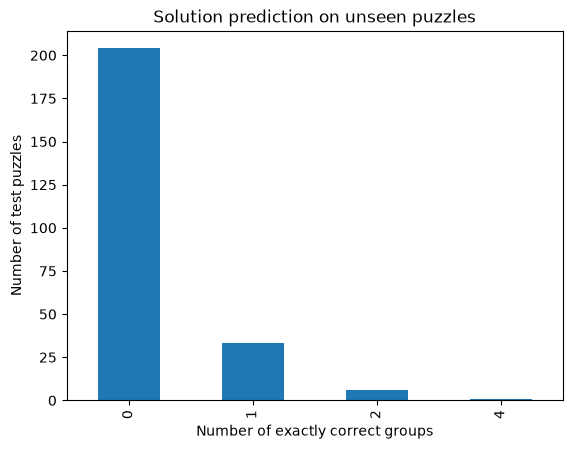

In [27]:
all_true_pairs = []
all_pair_probabilities = []
results = []

for puzzle in testing_puzzles:
    features, indices = pair_features(puzzle["words"])
    probabilities = classifier.predict_proba(features)[:, 1]
    true_pairs = [int(puzzle["groups"][i] == puzzle["groups"][j])
                  for i, j in indices]
    all_true_pairs.extend(true_pairs)
    all_pair_probabilities.extend(probabilities)

    predicted = predict_solution(puzzle["words"])
    actual_groups = []
    for color in set(puzzle["groups"]):
        actual_groups.append(frozenset(
            word for word, group in zip(puzzle["words"], puzzle["groups"])
            if group == color
        ))

    correct_groups = sum(frozenset(group) in actual_groups for group in predicted)
    results.append({
        "puzzle_date": puzzle["date"],
        "correct_groups": correct_groups,
        "fully_solved": int(correct_groups == 4)
    })

solution_results = pd.DataFrame(results)
pair_auc = roc_auc_score(all_true_pairs, all_pair_probabilities)
print(f"Pairwise ROC AUC: {pair_auc:.3f}")
print(f"Mean exact groups recovered: {solution_results.correct_groups.mean():.3f} of 4")
print(f"Fully solved puzzles: {solution_results.fully_solved.mean():.1%}")
print("Randomly grouped baseline: about 0.0088 exact groups per puzzle")

solution_results.to_csv("data/derived/solution_prediction_test_results.csv", index=False)
solution_results.correct_groups.value_counts().sort_index().plot.bar()
plt.xlabel("Number of exactly correct groups")
plt.ylabel("Number of test puzzles")
plt.title("Solution prediction on unseen puzzles")
plt.show()


### 14.4 Enter your own puzzle

Replace the example words below with 16 distinct words from any new Connections puzzle. The model outputs **groups**, not their category descriptions or NYT color labels. It is likely to struggle with synonyms and wordplay because its features mainly describe spelling patterns.

In [28]:
new_puzzle = [
    "APPLE", "DOG", "RED", "PIANO",
    "BANANA", "CAT", "BLUE", "GUITAR",
    "ORANGE", "HORSE", "GREEN", "VIOLIN",
    "GRAPE", "COW", "YELLOW", "DRUM"
]

for number, group in enumerate(predict_solution(new_puzzle), 1):
    print(f"Group {number}: {', '.join(group)}")


Group 1: BLUE, GREEN, COW, YELLOW
Group 2: DOG, RED, BANANA, GUITAR
Group 3: APPLE, CAT, ORANGE, HORSE
Group 4: PIANO, VIOLIN, GRAPE, DRUM


### 14.5 Interpretation and limitations

This is a **course-level supervised classification baseline**, not a general language understanding system. It does not use the saved pairwise semantic statistics to identify individual word pairs, because those CSVs do not contain word-pair identifiers. It also cannot name category themes. Its strengths and weaknesses are measured on later puzzles, not inferred from examples alone.

**Possible extension:** Compare this supervised classifier with K-means clustering of word embeddings, if the course exercises include embeddings and you have an appropriate model available. Avoid claiming that PCA or K-means alone enforces the four-by-four puzzle constraint.


## 15. Improved solution prediction: course-level model comparison

This section improves the earlier five-feature baseline without requiring deep learning or external pretrained models. It uses **TF-IDF**, **logistic regression**, **random forests**, **chronological validation**, and **constrained grouping**. These are standard feature engineering, classification, and model evaluation techniques.

**Fair comparison:** The original baseline is retained in Section 14. Here we rebuild features from *training puzzles only*, tune on a separate validation period, and evaluate once on the final test period. We never train using the true groups from validation or test puzzles.

**Important distinction:** TF-IDF character n-grams measure spelling patterns, **not semantic meaning**. The existing similarity tables do not identify the two words in each pair, so we cannot safely use those values to solve new puzzles. Adding a pretrained semantic embedding model would require an external model and is left as an optional extension, not silently included.

### 15.1 Split puzzles into training, validation and test periods

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from itertools import combinations

# Puzzles were sorted by date in Section 14.
# 60% train, 20% validation, 20% final test.
train_end = int(0.60 * len(puzzle_records))
validation_end = int(0.80 * len(puzzle_records))
solver_train = puzzle_records[:train_end]
solver_validation = puzzle_records[train_end:validation_end]
solver_test = puzzle_records[validation_end:]

print('Train puzzles:', len(solver_train))
print('Validation puzzles:', len(solver_validation))
print('Test puzzles:', len(solver_test))
print('Test starts:', solver_test[0]['date'].date())

# Fit the vectorizer using training words only.
training_vocabulary = [word for puzzle in solver_train for word in puzzle['words']]
char_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 4))
char_vectorizer.fit(training_vocabulary)

# Count repeated co-membership in historical training groups.
training_pair_counts = {}
for puzzle in solver_train:
    for i, j in combinations(range(16), 2):
        if puzzle['groups'][i] == puzzle['groups'][j]:
            key = tuple(sorted((puzzle['words'][i], puzzle['words'][j])))
            training_pair_counts[key] = training_pair_counts.get(key, 0) + 1

Train puzzles: 731
Validation puzzles: 244
Test puzzles: 244
Test starts: 2026-02-11


### 15.2 Explainable word-pair features

In [30]:
def make_pair_features(puzzle_words):
    """Return lexical features and the corresponding word-position pairs."""
    clean_words = [str(word).upper().strip() for word in puzzle_words]
    word_vectors = char_vectorizer.transform(clean_words)
    tfidf_similarity = (word_vectors @ word_vectors.T).toarray()

    features = []
    positions = []
    for i, j in combinations(range(16), 2):
        first = clean_words[i]
        second = clean_words[j]
        shared_start = 0
        shared_end = 0
        for k in (1, 2, 3):
            shared_start += int(len(first) >= k and len(second) >= k
                                and first[:k] == second[:k])
            shared_end += int(len(first) >= k and len(second) >= k
                              and first[-k:] == second[-k:])
        pair_key = tuple(sorted((first, second)))
        features.append([
            tfidf_similarity[i, j],
            shared_start,
            shared_end,
            abs(len(first) - len(second)),
            int(len(first) == len(second)),
            int(first[0] == second[0]),
            int(first[-1] == second[-1]),
            int(pair_key in training_pair_counts)
        ])
        positions.append((i, j))
    return np.asarray(features, dtype=float), positions

feature_names_solver = [
    'character TF-IDF similarity', 'shared prefix length (up to 3)',
    'shared suffix length (up to 3)', 'difference in word length',
    'same word length', 'same first letter', 'same last letter',
    'previously grouped in training'
]

def build_pair_dataset(puzzles):
    """Create 120 labeled pairs for each puzzle."""
    feature_rows = []
    labels = []
    for puzzle in puzzles:
        pair_features, pair_positions = make_pair_features(puzzle['words'])
        feature_rows.append(pair_features)
        labels.extend(int(puzzle['groups'][i] == puzzle['groups'][j])
                      for i, j in pair_positions)
    return np.vstack(feature_rows), np.asarray(labels)

X_train, y_train = build_pair_dataset(solver_train)
X_validation, y_validation = build_pair_dataset(solver_validation)
X_test, y_test = build_pair_dataset(solver_test)
print('Training pairs:', len(y_train), 'positive fraction:', round(y_train.mean(), 3))

Training pairs: 87720 positive fraction: 0.2


### 15.3 Compare logistic regression and random forest on validation data

In [31]:
# These are course-level classifiers; no deep learning is used.
solver_models = {
    'Logistic regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random forest': RandomForestClassifier(
        n_estimators=120, min_samples_leaf=15, max_features='sqrt',
        class_weight='balanced', random_state=42, n_jobs=-1
    )
}

validation_rows = []
for model_name, model in solver_models.items():
    model.fit(X_train, y_train)
    predicted_probabilities = model.predict_proba(X_validation)[:, 1]
    validation_rows.append({
        'model': model_name,
        'validation_pair_auc': roc_auc_score(y_validation, predicted_probabilities)
    })

validation_table = pd.DataFrame(validation_rows).sort_values(
    'validation_pair_auc', ascending=False
)
display(validation_table)
validation_table.to_csv(OUTPUT / 'solver_validation_comparison.csv', index=False)

# Choose the best classifier using validation data only.
selected_name = validation_table.iloc[0]['model']
selected_model = solver_models[selected_name]
print('Selected for the final test:', selected_name)

,model,validation_pair_auc
1,Random forest,0.564703
0,Logistic regression,0.535045


Selected for the final test: Random forest


### 15.4 Compare greedy grouping with constrained beam search

In [33]:
def probability_matrix(model, puzzle_words):
    """Estimate pairwise compatibility for the 16 words."""
    features, positions = make_pair_features(puzzle_words)
    probabilities = model.predict_proba(features)[:, 1]
    matrix = np.zeros((16, 16))
    for (i, j), probability in zip(positions, probabilities):
        matrix[i, j] = probability
        matrix[j, i] = probability
    return matrix


def group_score(group, matrix):
    """Total pair compatibility within one group of four."""
    return sum(matrix[i, j] for i, j in combinations(group, 2))


def solve_greedy(matrix):
    """Repeatedly choose the strongest available group of four."""
    remaining = list(range(16))
    solution = []
    while remaining:
        candidates = list(combinations(remaining, 4))
        best = max(candidates, key=lambda group: group_score(group, matrix))
        solution.append(best)
        remaining = [i for i in remaining if i not in best]
    return solution


def solve_beam(matrix, beam_width=20):
    """Search for four disjoint groups; keep the best 20 partial solutions.

    This is an approximate constrained search, not a proof of the global optimum.
    Every returned solution uses each word once and has four groups of four.
    """
    # Each state is (total_score, groups, remaining_word_positions).
    beam = [(0.0, [], tuple(range(16)))]
    for step in range(4):
        candidates = []
        for total, chosen, remaining in beam:
            # Anchor the smallest remaining position to avoid equivalent reorderings.
            anchor = remaining[0]
            for other_three in combinations(remaining[1:], 3):
                group = (anchor,) + other_three
                leftover = tuple(i for i in remaining if i not in group)
                candidates.append((total + group_score(group, matrix),
                                   chosen + [group], leftover))
        candidates.sort(key=lambda state: state[0], reverse=True)
        beam = candidates[:beam_width]
    return beam[0][1]


def evaluate_partition(predicted_groups, puzzle):
    """Count exact matches to the puzzle's four correct groups."""
    actual = {
        frozenset(i for i, label in enumerate(puzzle['groups']) if label == color)
        for color in set(puzzle['groups'])
    }
    matches = [frozenset(group) in actual for group in predicted_groups]
    return sum(matches), int(all(matches))

### 15.5 Select the grouping strategy using validation puzzles only

Beam search is not guaranteed to outperform greedy grouping. Select the grouping strategy on validation puzzles before inspecting test performance.

To keep this fully reproducible on an ordinary laptop, partition recovery is compared on the **first 80 puzzles** of the validation period. Pairwise AUC uses all 244 validation puzzles.

In [34]:
grouping_validation = []
for name, model in solver_models.items():
    for method_name, solver in [('Greedy', solve_greedy), ('Beam search', solve_beam)]:
        correct_counts = []
        for puzzle in solver_validation[:80]:
            matrix = probability_matrix(model, puzzle['words'])
            predicted = solver(matrix)
            correct, _ = evaluate_partition(predicted, puzzle)
            correct_counts.append(correct)
        grouping_validation.append({
            'model': name, 'grouping': method_name,
            'mean_correct_groups': np.mean(correct_counts)
        })
grouping_validation = pd.DataFrame(grouping_validation)
display(grouping_validation)
grouping_validation.to_csv(OUTPUT / 'solver_grouping_validation.csv', index=False)

# Select model and grouping by validation exact-group recovery.
chosen = grouping_validation.sort_values('mean_correct_groups', ascending=False).iloc[0]
selected_name = chosen['model']
selected_model = solver_models[selected_name]
selected_grouping = chosen['grouping']
selected_solver = solve_greedy if selected_grouping == 'Greedy' else solve_beam
print('Selected:', selected_name, '+', selected_grouping)


/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib worker

,model,grouping,mean_correct_groups
0,Logistic regression,Greedy,0.2500
1,Logistic regression,Beam search,0.0375
2,Random forest,Greedy,0.2375
3,Random forest,Beam search,0.0500


Selected: Logistic regression + Greedy


### 15.5 Evaluate final models on the untouched chronological test set

Pairwise AUC uses **all 244 test puzzles**. Exact-group recovery is computed on the **first 80 test puzzles** for both models and grouping strategies, making those comparisons like-for-like. This is a computational subset, not a full-test group recovery estimate.

/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib worker

,model,grouping,pair_auc_all_244_puzzles,n_puzzles_grouping,mean_correct_groups,fully_solved_fraction
0,Logistic regression,Greedy,0.5046,80,0.1875,0.0
1,Logistic regression,Beam search,0.5046,80,0.0375,0.0
2,Random forest,Greedy,0.5581,80,0.2000,0.0
3,Random forest,Beam search,0.5581,80,0.0750,0.0


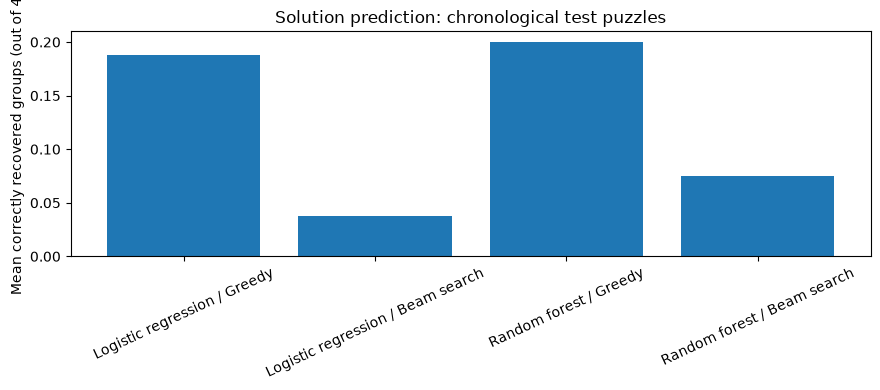

In [35]:
# Pairwise test AUC is measured once, after model selection.
# We also compare the two grouping strategies on the same puzzles.
solver_rows = []
solver_puzzle_rows = []
for model_name, model in solver_models.items():
    pair_probabilities = model.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, pair_probabilities)
    for method_name, solver in [('Greedy', solve_greedy), ('Beam search', solve_beam)]:
        group_counts = []
        fully_solved = []
        for puzzle in solver_test[:80]:
            matrix = probability_matrix(model, puzzle['words'])
            predicted_groups = solver(matrix)
            correct, solved = evaluate_partition(predicted_groups, puzzle)
            group_counts.append(correct)
            fully_solved.append(solved)
            solver_puzzle_rows.append({
                'puzzle_date': puzzle['date'], 'model': model_name,
                'grouping': method_name, 'correct_groups': correct,
                'fully_solved': solved
            })
        solver_rows.append({
            'model': model_name, 'grouping': method_name,
            'pair_auc_all_244_puzzles': test_auc,
            'n_puzzles_grouping': len(group_counts),
            'mean_correct_groups': np.mean(group_counts),
            'fully_solved_fraction': np.mean(fully_solved)
        })

solver_comparison = pd.DataFrame(solver_rows)
display(solver_comparison.round(4))
solver_comparison.to_csv(OUTPUT / 'solver_final_test_comparison.csv', index=False)
pd.DataFrame(solver_puzzle_rows).to_csv(
    OUTPUT / 'solver_test_puzzle_results.csv', index=False
)

fig, ax = plt.subplots(figsize=(9, 4))
labels = solver_comparison['model'] + ' / ' + solver_comparison['grouping']
ax.bar(labels, solver_comparison['mean_correct_groups'])
ax.set_ylabel('Mean correctly recovered groups (out of 4)')
ax.set_title('Solution prediction: chronological test puzzles')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

### 15.6 Compare exact recovery by group color

In [36]:
# A group can be matched to a color only during evaluation, not prediction.
color_results = []
for puzzle in solver_test[:80]:
    predicted = selected_solver(probability_matrix(selected_model, puzzle['words']))
    predicted_sets = {frozenset(group) for group in predicted}
    for color in ['yellow', 'green', 'blue', 'purple']:
        actual_positions = frozenset(
            i for i, label in enumerate(puzzle['groups']) if label == color
        )
        color_results.append({
            'color': color, 'correct': int(actual_positions in predicted_sets)
        })
color_table = pd.DataFrame(color_results).groupby('color').correct.agg(['mean', 'sum', 'count'])
display(color_table)
color_table.to_csv(OUTPUT / 'solver_accuracy_by_color.csv')

,mean,sum,count
color,,,
blue,0.0375,3,80
green,0.0500,4,80
purple,0.0125,1,80
yellow,0.0875,7,80


### 15.7 Enter 16 new words to predict their groups

In [37]:
def predict_new_connections(words_to_solve):
    """Return four groups using the selected classifier and beam search."""
    cleaned = [str(word).strip().upper() for word in words_to_solve]
    if len(cleaned) != 16 or len(set(cleaned)) != 16:
        raise ValueError('Enter exactly 16 distinct words.')
    matrix = probability_matrix(selected_model, cleaned)
    groups_of_indices = selected_solver(matrix)
    return [[cleaned[i] for i in group] for group in groups_of_indices]

# Replace these words with any unseen Connections puzzle.
new_words = [
    'APPLE', 'DOG', 'RED', 'PIANO',
    'BANANA', 'CAT', 'BLUE', 'GUITAR',
    'ORANGE', 'HORSE', 'GREEN', 'VIOLIN',
    'GRAPE', 'COW', 'YELLOW', 'DRUM'
]
for number, predicted_group in enumerate(predict_new_connections(new_words), 1):
    print(f'Predicted group {number}: {", ".join(predicted_group)}')

Predicted group 1: BLUE, GREEN, COW, YELLOW
Predicted group 2: DOG, RED, BANANA, GUITAR
Predicted group 3: CAT, ORANGE, VIOLIN, DRUM
Predicted group 4: APPLE, PIANO, HORSE, GRAPE


### 15.8 Interpretation and next steps

- **Model selection:** compare validation AUC first; do not pick the final model using the test results.
- **Group constraints:** both grouping methods guarantee exactly four non-overlapping groups of four. Beam search considers alternative partial solutions and may improve over greedy, but is **not an exact global optimizer**.
- **Interpretation:** a pairwise AUC near 0.5 means the classifier barely distinguishes correct from incorrect pairs. Good pairwise scores do not guarantee an entire puzzle is solved.
- **Wordplay limitation:** lexical TF-IDF cannot reliably recognize meaning, cultural references, or many purple-group tricks.
- **Semantic extension:** if your instructor approves fixed pretrained word embeddings, their cosine similarities could be added as a ninth pair feature, using the *same* logistic regression/random forest and evaluation workflow. That representation is not implemented here because it is not provided as word-pair-indexed data in the repository.
- **Reproducibility:** all newly generated CSVs are saved in `data/derived/`; source data stays unchanged.

## 16. Semantic solution prediction with Sentence Transformers

**Research question:** Does semantic relatedness improve the recovery of four correct groups in previously unseen puzzles?

The pretrained transformer is used **only to convert text to numeric vectors**. The statistical models remain BERN02-level logistic regression and random forest. No neural network is trained in this project.

**Important:** This optional extension needs `sentence-transformers` and a one-time download of the pretrained model. Install it in your notebook environment with `pip install sentence-transformers`. Internet is required the first time the model is downloaded. The previous lexical analysis works without it. This section has not been executed in the supplied archive because the package and pretrained model could not be downloaded in the preparation environment. **Do not interpret any unrun code as a measured improvement.**

We use the **same chronological train / validation / test split** as Section 15. Model selection uses only validation puzzles. Test puzzles are evaluated once after choosing the model and grouping algorithm.

### 16.1 Load a pretrained embedding model and cache word vectors

`all-MiniLM-L6-v2` maps a word or phrase to a numerical vector. Similar words often have similar vectors, but spelling tricks and phrase-completion puzzles may still be hard. To save time, encode each distinct word once and save the resulting vectors under `data/derived/`.

In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

try:
    from sentence_transformers import SentenceTransformer
except ImportError as error:
    raise ImportError(
        "Install the optional dependency: pip install sentence-transformers"
    ) from error

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

# Include words from every split because embedding is unsupervised and frozen.
# No puzzle answers or difficulty ratings are used to create embeddings.
all_solver_words = sorted({
    str(word).strip().upper()
    for puzzle in puzzle_records
    for word in puzzle["words"]
})

cache_dir = Path("data/derived")
cache_dir.mkdir(parents=True, exist_ok=True)
cache_file = cache_dir / "minilm_word_embeddings.npz"

if cache_file.exists():
    cache = np.load(cache_file)
    cached_words = cache["words"].tolist()
    if cached_words == all_solver_words:
        vectors = cache["vectors"]
        print("Loaded cached word embeddings")
    else:
        vectors = embedding_model.encode(
            all_solver_words, batch_size=64, show_progress_bar=True,
            normalize_embeddings=True
        )
        np.savez_compressed(cache_file, words=all_solver_words, vectors=vectors)
else:
    vectors = embedding_model.encode(
        all_solver_words, batch_size=64, show_progress_bar=True,
        normalize_embeddings=True
    )
    np.savez_compressed(cache_file, words=all_solver_words, vectors=vectors)

word_embeddings = dict(zip(all_solver_words, vectors))
print("Encoded", len(word_embeddings), "distinct words")

/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 538.12it/s]


Loaded cached word embeddings
Encoded 8827 distinct words


### 16.2 Add semantic similarity to the existing lexical features

Cosine similarity is the dot product of two normalized vectors. For each puzzle we calculate 120 pairwise similarities, then optionally append them to the spelling-based features from Section 15. This allows a fair comparison of **lexical-only**, **semantic-only**, and **combined** features.

In [52]:
def semantic_pair_features(puzzle_words):
    """Return cosine similarity for each of the 120 word pairs."""
    clean_words = [str(word).strip().upper() for word in puzzle_words]

    # Allow prediction on new words not present in the historical database.
    missing_words = [word for word in clean_words if word not in word_embeddings]
    if missing_words:
        new_vectors = embedding_model.encode(
            missing_words, normalize_embeddings=True
        )
        word_embeddings.update(zip(missing_words, new_vectors))

    word_vectors = np.array([word_embeddings[word] for word in clean_words])
    similarities = word_vectors @ word_vectors.T

    rows = []
    for i, j in combinations(range(16), 2):
        rows.append([similarities[i, j]])
    return np.asarray(rows)


def make_features(puzzle_words, feature_type):
    """Build lexical, semantic, or combined pair features."""
    lexical, positions = make_pair_features(puzzle_words)
    semantic = semantic_pair_features(puzzle_words)

    if feature_type == "lexical":
        return lexical, positions
    if feature_type == "semantic":
        return semantic, positions
    if feature_type == "combined":
        return np.column_stack([lexical, semantic]), positions
    raise ValueError("Unknown feature type")


def make_labeled_pairs(puzzles, feature_type):
    """Build a labeled pair dataset from complete puzzles."""
    all_features = []
    all_labels = []
    for puzzle in puzzles:
        features, positions = make_features(puzzle["words"], feature_type)
        labels = [
            int(puzzle["groups"][i] == puzzle["groups"][j])
            for i, j in positions
        ]
        all_features.append(features)
        all_labels.extend(labels)
    return np.vstack(all_features), np.asarray(all_labels)

print("Example cosine similarities:")
example_features = semantic_pair_features(solver_train[0]["words"])
print(example_features[:5].round(3).ravel())

Example cosine similarities:
[0.324 0.353 0.395 0.271 0.356]


### 16.3 Compare classifiers on validation puzzles

For each feature set, fit logistic regression and random forest on earlier puzzles. Choose the model using validation ROC AUC only. We keep test data untouched until the final evaluation.

In [53]:
feature_types = ["lexical", "semantic", "combined"]
semantic_models = {}
validation_scores = []

for feature_type in feature_types:
    X_train_sem, y_train_sem = make_labeled_pairs(solver_train, feature_type)
    X_valid_sem, y_valid_sem = make_labeled_pairs(solver_validation, feature_type)

    candidates = {
        "Logistic regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, class_weight="balanced")
        ),
        "Random forest": RandomForestClassifier(
            n_estimators=120, min_samples_leaf=15,
            class_weight="balanced", random_state=42, n_jobs=-1
        )
    }

    for model_name, model in candidates.items():
        model.fit(X_train_sem, y_train_sem)
        probabilities = model.predict_proba(X_valid_sem)[:, 1]
        auc = roc_auc_score(y_valid_sem, probabilities)
        key = (feature_type, model_name)
        semantic_models[key] = model
        validation_scores.append({
            "features": feature_type,
            "classifier": model_name,
            "validation_auc": auc
        })

semantic_validation = pd.DataFrame(validation_scores)
semantic_validation = semantic_validation.sort_values(
    "validation_auc", ascending=False
)
display(semantic_validation)
semantic_validation.to_csv(
    "data/derived/semantic_solver_validation.csv", index=False
)

,features,classifier,validation_auc
2,semantic,Logistic regression,0.650775
3,semantic,Random forest,0.628527
5,combined,Random forest,0.571524
1,lexical,Random forest,0.564703
0,lexical,Logistic regression,0.537924
4,combined,Logistic regression,0.494761


### 16.4 Select a grouping strategy using validation data

A high pairwise AUC does not guarantee that all four groups can be recovered. Evaluate the top three validation classifiers with greedy grouping and beam search. Both methods return exactly four non-overlapping groups of four. The best **validation** combination is selected for the final test.

In [54]:
def semantic_probability_matrix(model, puzzle_words, feature_type):
    """Create a symmetric 16 × 16 pairwise compatibility matrix."""
    features, positions = make_features(puzzle_words, feature_type)
    probabilities = model.predict_proba(features)[:, 1]
    matrix = np.zeros((16, 16))
    for (i, j), probability in zip(positions, probabilities):
        matrix[i, j] = probability
        matrix[j, i] = probability
    return matrix

validation_group_scores = []
top_candidates = semantic_validation.head(3)

for _, row in top_candidates.iterrows():
    feature_type = row["features"]
    classifier = row["classifier"]
    model = semantic_models[(feature_type, classifier)]

    for method_name, grouping_method in [
        ("Greedy", solve_greedy), ("Beam search", solve_beam)
    ]:
        correct_groups = []
        for puzzle in solver_validation[:80]:
            matrix = semantic_probability_matrix(
                model, puzzle["words"], feature_type
            )
            predicted_groups = grouping_method(matrix)
            correct, _ = evaluate_partition(predicted_groups, puzzle)
            correct_groups.append(correct)

        validation_group_scores.append({
            "features": feature_type,
            "classifier": classifier,
            "grouping": method_name,
            "mean_correct_groups": np.mean(correct_groups)
        })

grouping_results = pd.DataFrame(validation_group_scores)
grouping_results = grouping_results.sort_values(
    "mean_correct_groups", ascending=False
)
display(grouping_results)
grouping_results.to_csv(
    "data/derived/semantic_grouping_validation.csv", index=False
)

best_choice = grouping_results.iloc[0]
best_features = best_choice["features"]
best_classifier = best_choice["classifier"]
best_grouping = best_choice["grouping"]
best_model = semantic_models[(best_features, best_classifier)]
best_solver = solve_greedy if best_grouping == "Greedy" else solve_beam
print("Selected:", best_features, best_classifier, best_grouping)

,features,classifier,grouping,mean_correct_groups
0,semantic,Logistic regression,Greedy,0.2625
4,combined,Random forest,Greedy,0.2625
2,semantic,Random forest,Greedy,0.1750
1,semantic,Logistic regression,Beam search,0.1625
5,combined,Random forest,Beam search,0.1250
3,semantic,Random forest,Beam search,0.0625


Selected: semantic Logistic regression Greedy


### 16.5 Evaluate once on the chronological test set

Report pairwise ROC AUC on all held-out puzzles, then evaluate exact group recovery on the same first 80 held-out puzzles used for grouping comparisons in Section 15. Report how often the entire puzzle is solved. The final metrics are calculated when this section is run; no scores are assumed in advance.

In [55]:
X_test_sem, y_test_sem = make_labeled_pairs(solver_test, best_features)
test_probabilities = best_model.predict_proba(X_test_sem)[:, 1]
test_auc = roc_auc_score(y_test_sem, test_probabilities)

test_rows = []
for puzzle in solver_test[:80]:
    matrix = semantic_probability_matrix(
        best_model, puzzle["words"], best_features
    )
    predicted_groups = best_solver(matrix)
    correct, solved = evaluate_partition(predicted_groups, puzzle)
    test_rows.append({
        "puzzle_date": puzzle["date"],
        "correct_groups": correct,
        "fully_solved": solved
    })

semantic_test_puzzles = pd.DataFrame(test_rows)
semantic_test_puzzles.to_csv(
    "data/derived/semantic_solver_test_puzzles.csv", index=False
)
semantic_test_summary = pd.DataFrame([{
    "features": best_features,
    "classifier": best_classifier,
    "grouping": best_grouping,
    "test_pair_auc": test_auc,
    "test_puzzles_for_grouping": len(semantic_test_puzzles),
    "mean_correct_groups": semantic_test_puzzles["correct_groups"].mean(),
    "fully_solved_fraction": semantic_test_puzzles["fully_solved"].mean()
}])
display(semantic_test_summary)
semantic_test_summary.to_csv(
    "data/derived/semantic_solver_test_summary.csv", index=False
)

# Direct comparison against the earlier lexical models on the same 80 puzzles.
if "solver_comparison" in globals():
    display(solver_comparison[[
        "model", "grouping", "pair_auc_all_244_puzzles",
        "mean_correct_groups", "fully_solved_fraction"
    ]])

,features,classifier,grouping,test_pair_auc,test_puzzles_for_grouping,mean_correct_groups,fully_solved_fraction
0,semantic,Logistic regression,Greedy,0.642862,80,0.2875,0.0


,model,grouping,pair_auc_all_244_puzzles,mean_correct_groups,fully_solved_fraction
0,Logistic regression,Greedy,0.504551,0.1875,0.0
1,Logistic regression,Beam search,0.504551,0.0375,0.0
2,Random forest,Greedy,0.558081,0.2000,0.0
3,Random forest,Beam search,0.558081,0.0750,0.0


### 16.6 Predict a new puzzle from 16 words

Replace `new_words` with the 16 visible words from a new puzzle. No category names or answer key are needed. The four predicted groups are **guesses**, and the model may struggle with wordplay or multiple-meaning clues.

In [56]:
def predict_semantic_connections(puzzle_words):
    """Predict four non-overlapping groups of four from 16 words."""
    clean_words = [str(word).strip().upper() for word in puzzle_words]
    if len(clean_words) != 16 or len(set(clean_words)) != 16:
        raise ValueError("Provide exactly 16 distinct words")

    matrix = semantic_probability_matrix(
        best_model, clean_words, best_features
    )
    groups = best_solver(matrix)
    return [[clean_words[i] for i in group] for group in groups]

# Reuse the illustrative 16-word example from the earlier section.
for number, group in enumerate(predict_semantic_connections(new_words), 1):
    print(f"Predicted group {number}: {', '.join(group)}")

Predicted group 1: RED, BLUE, GREEN, YELLOW
Predicted group 2: DOG, CAT, HORSE, COW
Predicted group 3: PIANO, GUITAR, VIOLIN, DRUM
Predicted group 4: APPLE, BANANA, ORANGE, GRAPE


### 16.7 Interpretation and limitations

- Compare **validation** results when choosing models; use **test** results only for final reporting.
- The pretrained embeddings come from an external model and are **not learned from the Connections answers**. State this clearly in your project report.
- Pairwise ROC AUC, correctly recovered groups, and fully solved puzzles measure different aspects of performance.
- The grouping search is a practical heuristic and may miss the globally optimal partition.
- Embeddings may work well for ordinary semantic categories but miss puns, homophones, missing-word phrases, and cultural references.
- All CSV outputs are stored under `data/derived/`. The `.npz` embedding cache is also there but is not a CSV because it stores a numeric matrix efficiently.
- The optional transformer dependency is beyond what the syllabus explicitly names; the **classification, model selection, and evaluation** remain within the course's stated scope.

## 17. Solve one Connections puzzle using clustering

This **unsupervised** solver is different from Section 11, which clusters entire puzzles. Here we cluster the **16 words of one puzzle** into four groups of four.

1. Sentence Transformers converts each word into a semantic embedding.
2. K-means proposes four centers.
3. A constrained assignment step ensures exactly four words per group.
4. We repeat from several initial centers and choose the grouping with the highest within-group similarity.

The model is a **fixed pretrained feature extractor**, not a neural network trained in this project. Clustering and evaluation are the statistical-learning methods. Wordplay and emoji puzzles may not be represented well.

Install once if needed: `pip install sentence-transformers`. The model downloads on first use. The same code is available as `clustering_solver.py` for running outside Jupyter.

In [41]:
from clustering_solver import load_encoder, solve_puzzle, evaluate_puzzles

# Download/load the pretrained semantic model once.
clustering_encoder = load_encoder()

# Replace these 16 example words with the words in your puzzle.
clustering_example = [
    "APPLE", "DOG", "RED", "PIANO",
    "BANANA", "CAT", "BLUE", "GUITAR",
    "ORANGE", "HORSE", "GREEN", "VIOLIN",
    "GRAPE", "COW", "YELLOW", "DRUM"
]

predicted_groups = solve_puzzle(clustering_example, clustering_encoder)
for number, group in enumerate(predicted_groups, start=1):
    print(f"Group {number}: {', '.join(group)}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1429.00it/s]


Group 1: DOG, CAT, HORSE, COW
Group 2: RED, BLUE, GREEN, YELLOW
Group 3: APPLE, BANANA, ORANGE, GRAPE
Group 4: PIANO, GUITAR, VIOLIN, DRUM


### 17.1 Evaluate on unseen puzzles

Clustering is unsupervised, so no puzzle answers are used during prediction. We evaluate on the most recent 30 puzzles, using the true groups **only to score the predictions**. Results are saved under `data/derived/`.

This section reports exact recovered groups and fully solved puzzles, so it can be compared with the supervised solver. The clustering model uses a pretrained representation learned from external text; it is therefore not a purely dataset-trained approach. The special emoji puzzle is excluded if it occurs in the evaluation window.

In [42]:
clustering_results = evaluate_puzzles(clustering_encoder, n_test=30)
display(clustering_results.head())

print("Correct groups per puzzle:")
display(clustering_results["correct_groups"].value_counts().sort_index())

Puzzles evaluated: 30
Mean correct groups: 0.433 / 4
Fully solved: 0.0%


,puzzle_date,correct_groups,fully_solved
0,2026-09-13,0,0
1,2026-09-14,0,0
2,2026-09-15,0,0
3,2026-09-16,0,0
4,2026-09-17,0,0


Correct groups per puzzle:


correct_groups
0    20
1     7
2     3
Name: count, dtype: int64

### 17.2 Interpretation

Compare the clustering solver's average recovered groups and fully solved rate with the supervised models. Do not assume clustering performs better without running the evaluation. A complete puzzle is a stricter criterion than finding individual related pairs. K-means assumes geometrically compact groups; Connections often uses puns, homophones, or hidden patterns that semantic embeddings may miss.

**Reproducibility:** `clustering_solver.py` contains the algorithm, the pretrained model name is fixed, the random seed is fixed, and evaluation results are exported to `data/derived/clustering_solver_test_results.csv`. For a direct model comparison, use exactly the same held-out puzzle dates for both methods.